# Notebook 1: EDA — The Silk Road as a Network

**Goal:** Build the raw node and edge dataset for the China–Central Asia–Europe
exchange network (~200 BC – 1400 AD), using the Pleiades gazetteer of ancient
places (Institute for the Study of the Ancient World, NYU / Ancient World
Mapping Center, UNC Chapel Hill). Data: https://pleiades.stoa.org

This notebook filters the full gazetteer down to our corridor and time window,
and does first-pass exploration before any network analysis.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import os

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)


if os.path.exists("/kaggle/input"):
    RAW_DIR = "/kaggle/input/pleiades-silk-road-raw" 
else:
    RAW_DIR = "data"

DATA = RAW_DIR
plt.rcParams["figure.figsize"] = (10, 6)

## 1.1 Load raw Pleiades tables

In [2]:
places = pd.read_csv(f"{DATA}/places.csv", low_memory=False)
loc = pd.read_csv(f"{DATA}/location_points.csv", low_memory=False)
conn = pd.read_csv(f"{DATA}/connections.csv", low_memory=False)

print(f"Total places in Pleiades gazetteer: {len(places):,}")
print(f"Total location points (with coordinates + dates): {len(loc):,}")
print(f"Total connections (edges) in gazetteer: {len(conn):,}")

Total places in Pleiades gazetteer: 42,318
Total location points (with coordinates + dates): 25,129
Total connections (edges) in gazetteer: 14,973


## 1.2 Filter to the Silk Road corridor

Bounding box: roughly Rome (~12°E) in the west to China's eastern seaboard
(~115°E) in the east, latitude 15°N–55°N. This deliberately over-includes —
we'll narrow further once we look at actual connectivity.

In [3]:
LON_MIN, LON_MAX = 0, 115
LAT_MIN, LAT_MAX = 15, 55

corridor = places[
    (places["representative_longitude"] >= LON_MIN)
    & (places["representative_longitude"] <= LON_MAX)
    & (places["representative_latitude"] >= LAT_MIN)
    & (places["representative_latitude"] <= LAT_MAX)
].copy()

print(f"Places within corridor bounding box: {len(corridor):,} "
      f"({len(corridor)/len(places):.1%} of full gazetteer)")

Places within corridor bounding box: 30,461 (72.0% of full gazetteer)


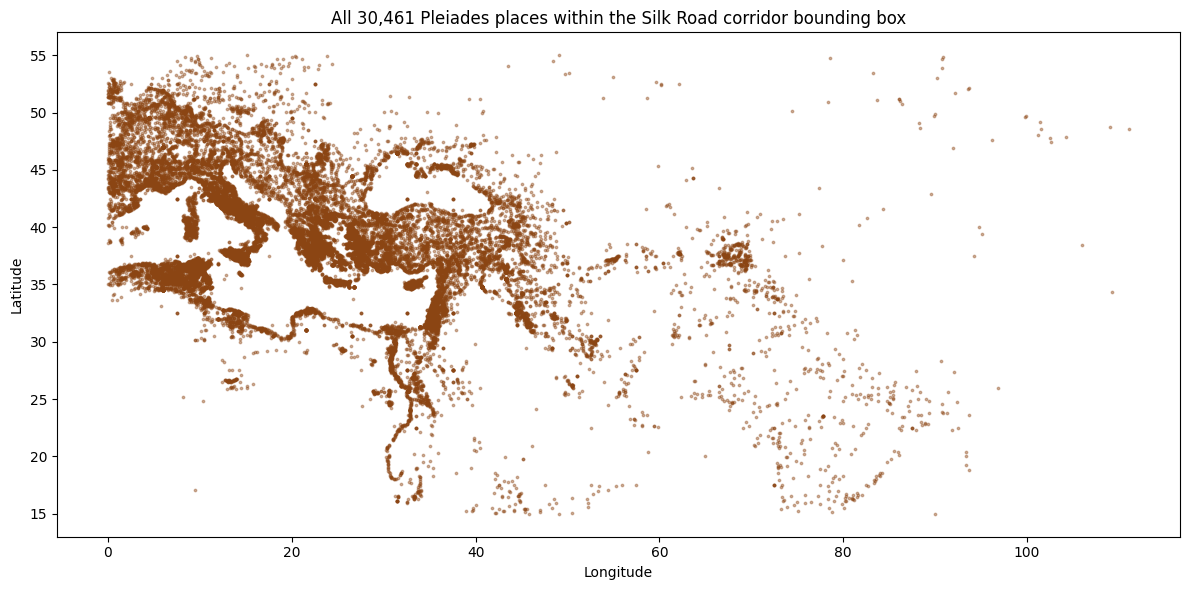

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(corridor["representative_longitude"], corridor["representative_latitude"],
           s=3, alpha=0.4, color="#8B4513")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"All {len(corridor):,} Pleiades places within the Silk Road corridor bounding box")
plt.tight_layout()
plt.savefig("outputs/01_corridor_scatter.png", dpi=120)
plt.show()

## 1.3 Extract edges (connections) within the corridor

Each connection links a `place_id` to a `connects_to` URI. We extract the
target place id and keep only edges where **both** endpoints fall inside
the corridor.

In [5]:
def extract_id(uri):
    if pd.isna(uri):
        return None
    m = re.search(r"/places/(\d+)", str(uri))
    return int(m.group(1)) if m else None

conn["connects_to_id"] = conn["connects_to"].apply(extract_id)
corridor_ids = set(corridor["id"])

edges = conn[
    conn["place_id"].isin(corridor_ids) & conn["connects_to_id"].isin(corridor_ids)
].copy()

print(f"Edges with both endpoints inside the corridor: {len(edges):,}")

Edges with both endpoints inside the corridor: 12,431


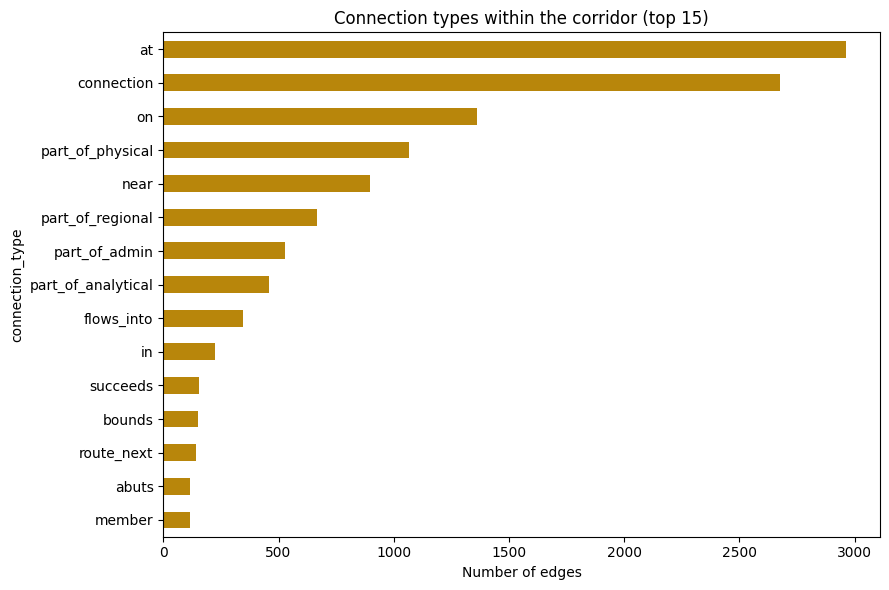

In [6]:
type_counts = edges["connection_type"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(9, 6))
type_counts.sort_values().plot(kind="barh", ax=ax, color="#B8860B")
ax.set_xlabel("Number of edges")
ax.set_title("Connection types within the corridor (top 15)")
plt.tight_layout()
plt.savefig("outputs/02_connection_types.png", dpi=120)
plt.show()

Most connection types (`at`, `on`, `part_of_*`, `near`) describe **spatial
containment** (e.g. a temple `at` a city), not trade relationships. The
types we actually care about for a trade/exchange network are the explicit
relational ones: `route_next`, `connection`, `flows_into` (rivers used as
trade arteries), `succeeds` (site succession over time), `abuts`, `bounds`.

In [7]:
TRADE_RELEVANT_TYPES = ["route_next", "connection", "flows_into", "succeeds", "abuts", "bounds", "near"]
trade_edges = edges[edges["connection_type"].isin(TRADE_RELEVANT_TYPES)]
print(f"Trade/route-relevant edges: {len(trade_edges):,}")
print(trade_edges["connection_type"].value_counts())

Trade/route-relevant edges: 4,483
connection_type
connection    2678
near           897
flows_into     344
succeeds       155
bounds         149
route_next     142
abuts          118
Name: count, dtype: int64


## 1.4 Temporal coverage

The target window is **200 BC – 1400 AD** (classical Silk Road through
just before the maritime shift). Check how much of the dated data falls
inside it.

In [8]:
YEAR_MIN, YEAR_MAX = -200, 1400

dated_edges = edges[edges["year_after_which"].notna() | edges["year_before_which"].notna()]
in_window = dated_edges[
    (dated_edges["year_after_which"].fillna(-99999) <= YEAR_MAX)
    & (dated_edges["year_before_which"].fillna(99999) >= YEAR_MIN)
]

print(f"Edges with any date info: {len(dated_edges):,} / {len(edges):,}")
print(f"Dated edges overlapping our {YEAR_MIN} to {YEAR_MAX} window: {len(in_window):,}")

Edges with any date info: 3,349 / 12,431
Dated edges overlapping our -200 to 1400 window: 1,843


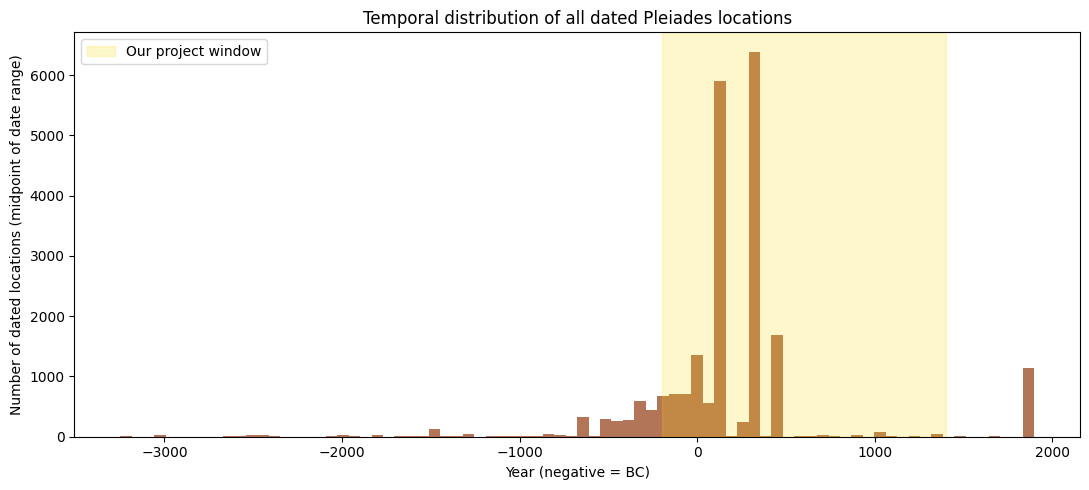

In [9]:
loc_dated = loc[loc["year_after_which"].notna() | loc["year_before_which"].notna()].copy()
midpoint = loc_dated[["year_after_which", "year_before_which"]].mean(axis=1)
midpoint = midpoint[(midpoint >= -3300) & (midpoint <= 1900)]  # sanity clip

fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(midpoint, bins=80, color="#A0522D", alpha=0.8)
ax.axvspan(YEAR_MIN, YEAR_MAX, color="gold", alpha=0.2, label="Our project window")
ax.set_xlabel("Year (negative = BC)")
ax.set_ylabel("Number of dated locations (midpoint of date range)")
ax.set_title("Temporal distribution of all dated Pleiades locations")
ax.legend()
plt.tight_layout()
plt.savefig("outputs/03_temporal_coverage.png", dpi=120)
plt.show()

## 1.5 Central Asia check — is our own region well represented?

In [10]:
LON_MIN_CA, LON_MAX_CA = 50, 80
LAT_MIN_CA, LAT_MAX_CA = 30, 45

central_asia = corridor[
    (corridor["representative_longitude"] >= LON_MIN_CA)
    & (corridor["representative_longitude"] <= LON_MAX_CA)
    & (corridor["representative_latitude"] >= LAT_MIN_CA)
    & (corridor["representative_latitude"] <= LAT_MAX_CA)
]
ca_ids = set(central_asia["id"])
ca_edges = edges[edges["place_id"].isin(ca_ids) | edges["connects_to_id"].isin(ca_ids)]

print(f"Places in Central Asia box: {len(central_asia):,}")
print(f"Edges touching Central Asia: {len(ca_edges):,}")
print()
key_sites = ["Merv", "Samarkand", "Bukhara", "Nisa", "Bactra"]
for site in key_sites:
    hits = places[places["title"].str.contains(site, case=False, na=False)]
    if len(hits):
        row = hits.iloc[0]
        print(f"  {row['title']:40s} lat={row['representative_latitude']:.2f}  lon={row['representative_longitude']:.2f}")

Places in Central Asia box: 706
Edges touching Central Asia: 169

  Margiana/Margush/Merv                    lat=37.66  lon=62.19
  Bukhara                                  lat=39.77  lon=64.42
  New Nisa                                 lat=37.97  lon=58.20
  Bactra/Zariaspa                          lat=36.77  lon=66.90


## 1.6 Save filtered node & edge tables for Notebook 2

In [11]:
corridor.to_csv("data/nodes_corridor.csv", index=False)
edges.to_csv("data/edges_corridor.csv", index=False)
trade_edges.to_csv("data/edges_trade_relevant.csv", index=False)

print("Saved:")
print(f"  data/nodes_corridor.csv          ({len(corridor):,} rows)")
print(f"  data/edges_corridor.csv          ({len(edges):,} rows)")
print(f"  data/edges_trade_relevant.csv    ({len(trade_edges):,} rows)")

Saved:
  data/nodes_corridor.csv          (30,461 rows)
  data/edges_corridor.csv          (12,431 rows)
  data/edges_trade_relevant.csv    (4,483 rows)


## Summary

- **30,461** places fall within the broad Silk Road corridor bounding box
- **12,431** edges connect two in-corridor places; of these, a smaller
  "trade-relevant" subset (route_next, flows_into, succeeds, etc.) captures
  actual route/relationship structure rather than pure spatial containment
- Temporal metadata exists for the majority of dated locations, with solid
  coverage inside our 200 BC – 1400 AD window
- Central Asia — including key sites tied to Turkmenistan (Merv, Nisa) — is
  represented with real coordinates and descriptions

**Next (Notebook 2):** construct the actual `networkx` graph from these
filtered tables, and compute first-pass structural stats (degree distribution,
connected components) before moving to time-sliced centrality analysis.